In [2]:
import numpy as np
from fit_file import X_sq
import sympy as sp

In [3]:
#GEMIDDELDES EN FOUTEN, proef 1
data_fake = "164.5+2/60 165+2/60 164.5+10/60 164.5+5/60 165.5+7/60 164.5+2/60 164.5+10/60 164.5+2/60 163.5+3/60 164 164 164+3/60 163 163+6/60 163 163+6/60 163 163 163+3/60 163 162.5+8/60 162.5+5/60 162.5 162.5+11/60 162.5+2/60 162.5+10/60 162.5+13/60 162.5+8/60 162 162.5+12/60 162 162"
data_1 = [eval(i) for i in data_fake.split(" ")]

nulhoek = (212+9/60) * np.pi/180

d1 = np.array(data_1[0:4]) * np.pi/180 - nulhoek
d2 = np.array(data_1[4:8]) * np.pi/180 - nulhoek
d3 = np.array(data_1[8:12]) * np.pi/180 - nulhoek
d4 = np.array(data_1[12:16]) * np.pi/180 - nulhoek
d5 = np.array(data_1[16:20]) * np.pi/180 - nulhoek
d6 = np.array(data_1[20:24]) * np.pi/180 - nulhoek
d7 = np.array(data_1[24:28]) * np.pi/180 - nulhoek
d8 = np.array(data_1[28:32]) * np.pi/180 - nulhoek

d1_gem = (np.sum(d1) / 4)
d2_gem = (np.sum(d2) / 4)
d3_gem = (np.sum(d3) / 4)
d4_gem = (np.sum(d4) / 4)
d5_gem = (np.sum(d5) / 4)
d6_gem = (np.sum(d6) / 4)
d7_gem = (np.sum(d7) / 4)
d8_gem = (np.sum(d8) / 4)

lijst_hoeken = [d1, d2, d3, d4, d5, d6, d7, d8] #lijst met lijsten
lijst_hoeken_gem = [d1_gem, d2_gem, d3_gem, d4_gem, d5_gem, d6_gem, d7_gem, d8_gem] #rad
fout_hoeken = [] #rad, systematische fout nog niet in rekening gebracht
for i in range(len(lijst_hoeken)):
    s = np.sqrt(1/3 * np.sum((lijst_hoeken[i] - lijst_hoeken_gem[i])**2))
    fout_hoeken.append(s) #pure statistscihe fouten, NOG DELEN DOOR SQRT(4) ALS WE +- DOEN!!!!!!!!!!!!!!!!!!

print(np.array(lijst_hoeken_gem) * 180/np.pi)
print(np.array(fout_hoeken) / np.sqrt(4))

[-47.44583333 -47.3125     -48.25       -49.1        -49.1375
 -49.55       -49.5125     -49.975     ]
[0.00197424 0.00456607 0.00204658 0.00050383 0.00021817 0.00068219
 0.0006757  0.00305433]


In [4]:
#model

def brekingsindex(minimum_hoek):
    alpha = 60 * np.pi/180
    n = (np.sin((minimum_hoek + alpha)/2)) / (np.sin(alpha / 2))
    return n

def afgeleide_n(delta, alpha):
    d, a = sp.symbols('d a')
    n = sp.Function('n')
    n = (sp.sin((d+a)/2))/(sp.sin(a/2))
    afg = sp.diff(n, d)
    afg_subs = float(afg.subs([(d, delta), (a, alpha)]))
    return afg_subs

brekingsindex_lijst = [] #geen eenheden
for i in lijst_hoeken_gem:
    n = brekingsindex(i)
    brekingsindex_lijst.append(n)


fout_breking = [] #geen index
for i in range(len(lijst_hoeken_gem)):
    alpha = 60 * np.pi/180
    fout_hoek = (2 * np.sqrt(2)) * np.pi/180
    s = np.sqrt((afgeleide_n(lijst_hoeken_gem[i], alpha))**2 * fout_hoek**2)
    fout_breking.append(s)




---------START--------------------------------------------------------------------------------------------------


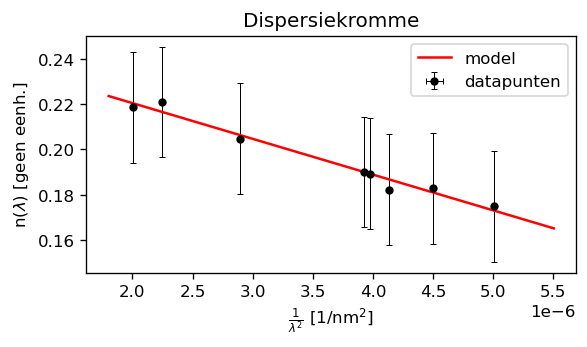

For parameter C        :     Minimum at       0.25224694     ;     68% CI = [      0.23913675,       0.26535713]
For parameter B        :     Minimum at  -15855.48869519     ;     68% CI = [ -19376.86498741,  -12334.20396964]
----------------------------------------------------------------------------------------------------------------
Minimal χ² value       :     χ²_min           0.08745687
Reduced χ² value       :     χ²_red           0.01457614
P-value                :     p-value          0.99998651


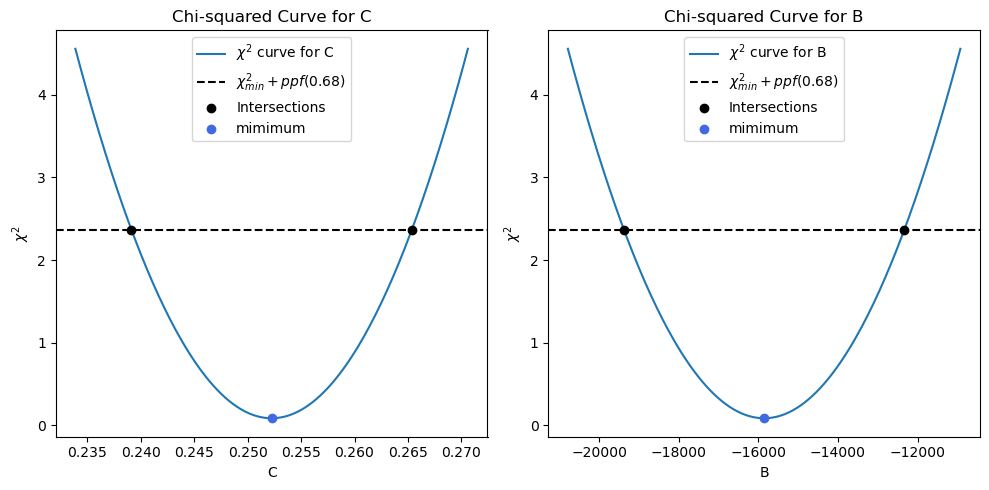

----------END---------------------------------------------------------------------------------------------------

[0.0245347  0.02453155 0.02455304 0.0245711  0.02457187 0.02458012
 0.02457938 0.02458829]


In [5]:
#fitten
def model(params, x):
    C, B = params
    return C + B * x

niet_xwaarden = np.array([706.5, 667.8, 587.5, 504.8, 501.6, 492.1, 471.3, 447.1]) #nm

x = 1/(niet_xwaarden**2) #1/(nm)**2
y = np.array(brekingsindex_lijst)

dx = np.array([0 for i in range(len(x))])
dy = np.array(fout_breking) / 2

param_names = ["C", "B"]

data_fit = ((x, dx), (y, dy))
x_label = r"$\frac{1}{\lambda^2}$ [1/$\text{nm}^2$]"
y_label = r"n($\lambda$) [geen eenh.]"
X_sq(data_fit, param_names, ( 0.24853182, -14966.34425076), model, graf1_x_label = x_label, graf1_y_label = y_label, graf1_title = "Dispersiekromme")
print(dy)


In [14]:
#GEMIDDELDES EN FOUTEN, proef 2

data_2_fake = "164 163.5+17/60 163.5+2/60 163.5+2/60 161.5+14/60 162"
data_2 = [eval(i) for i in data_2_fake.split(" ")]

d12 = np.array(data_2[0: 2]) * np.pi/180 - nulhoek
d22 = np.array(data_2[2: 4]) * np.pi/180 - nulhoek
d32 = np.array(data_2[4: 6]) * np.pi/180 - nulhoek

d12_gem = (np.sum(d12)/2)
d22_gem = (np.sum(d22)/2)
d32_gem = (np.sum(d32)/2)

lijst_hoeken_2 = [d12, d22, d32]
lijst_hoeken_gem_2 = [d12_gem, d22_gem, d32_gem]
fout_hoeken_2 = []
for i in range(len(lijst_hoeken_2)):
    s = np.sqrt(1/3 * np.sum((lijst_hoeken_2[i] - lijst_hoeken_gem_2[i])**2))
    fout_hoeken_2.append(s / np.sqrt(2))

print(fout_hoeken_2)
print(2*np.sqrt(2) * np.pi/180)
print(np.array(lijst_hoeken_gem_2) * 180 / np.pi)

[0.0010916385062520503, 0.0, 0.0013435550846180263]
0.049365365979537404
[-48.25833333 -48.61666667 -50.28333333]


In [7]:
#golflengtes om stof te achterhalen
C_fit =  0.25224445
B_fit = -15855.08224612

C_fout = np.abs(C_fit - 0.23907109)
B_fout = np.abs(B_fit - -19391.95097264)

n_waardes = []
fout_n = []
for i in range(len(lijst_hoeken_gem_2)):
    alpha = 60 * np.pi/180
    n = brekingsindex(lijst_hoeken_gem_2[i])
    dn = np.sqrt((afgeleide_n(lijst_hoeken_gem_2[i], alpha))**2 * (2*np.sqrt(2) * np.pi/180)**2)
    n_waardes.append(n)
    fout_n.append(dn)

lambda_waardes = []
x_opl = []
for i in n_waardes:
    x = sp.symbols('x')
    opl = sp.solve(sp.Eq(i, C_fit + B_fit * x), x)
    x_opl.append(opl[0])
    lambda_waardes.append((sp.sqrt(1/opl[0]))) #nm

#fout wordt berekend met x = (n-C)/B, op alle drie een fout → foutenpropagatie

def fout_l(nval, Cval, Bval, fout_n, fout_C, fout_B):
    l = sp.Function('x')
    n, C, B = sp.symbols('n C B')
    l = sp.sqrt(1 / ((n-C)/B))
    s_func = sp.sqrt(sp.diff(l, n)**2 * fout_n**2 + sp.diff(l, B)**2 * fout_B**2 + sp.diff(l, C)**2 * fout_C**2)
    s = s_func.subs([(n, nval), (C, Cval), (B, Bval)])
    return s

fouten_lambda = []
for i in range(len(x_opl)):
    s = fout_l(n_waardes[i], C_fit, B_fit, fout_n[i], C_fout, B_fout)
    fouten_lambda.append(s)

print(lambda_waardes)
print(fouten_lambda)




[576.702750851558, 542.390930184243, 437.433839563516]
[314.184191456006, 262.968310584246, 142.993725915795]
